In [143]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math


# PRELIMINAR + FIDELIDAD
from scipy.stats import chi2, chi2_contingency, spearmanr, ks_2samp
from sklearn.decomposition import PCA
from scipy.stats import zscore
from sdv.evaluation.single_table import get_column_plot
from sdv.metadata import SingleTableMetadata

# UTILIDAD
from sklearn.model_selection import train_test_split
from scipy.optimize import minimize
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, r2_score
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test
import matplotlib.ticker as mticker
from sklearn.preprocessing import LabelEncoder
 
# PRIVACIDAD
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

import importlib
import Functions_graphs
from matplotlib.colors import to_rgb, to_hex
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

import warnings
warnings.filterwarnings("ignore")



importlib.reload(Functions_graphs)

<module 'Functions_graphs' from 'c:\\Users\\DiegoGonzalez\\Desktop\\CopulaGAN\\scrips\\Functions_graphs.py'>

In [144]:
colores = {"GC":"red", "CTGAN":"blue", "C-GAN":"purple", "TVAE":"green"}

In [145]:
# INPUT
seed = [42]

train_path = r'..\data_train\train_df_seed' + str(seed[0]) + '.parquet'
test_path = r'..\data_test\test_df_seed ' + str(seed[0]) + '.parquet'
real_path = r'..\data\preprocesada\final_dataset.parquet'

df_train = pd.read_parquet(train_path, engine='pyarrow')
df_test = pd.read_parquet(test_path, engine='pyarrow')
df_real = pd.read_parquet(real_path, engine='pyarrow')

In [146]:
TARGET_COL = "Death"          # target óptimo para tu dataset oncológico
ID_COL     = "Patient_ID"         # columna ID a eliminar
 
SYNTH_PATHS = {
    "GC":               r'..\results\full_finals\copula_synth_best.parquet', 
    "CTGAN":              r'..\results\full_finals\synthetic_CTGAN.parquet', 
    "C-GAN":           r'..\results\full_finals\synthetic_final_CopulaGAN_seed42.parquet', 
    "TVAE":              r'..\results\full_finals\tvae_result_best.parquet', 
}

dfs_synth = {}

for i, path in SYNTH_PATHS.items():
    if path:
        dfs_synth[i] = pd.read_parquet(path, engine='pyarrow')


df_real = df_real.convert_dtypes()

In [147]:
for i, df in dfs_synth.items():
    print(i, df.shape)

GC (353, 42)
CTGAN (353, 42)
C-GAN (353, 42)
TVAE (353, 42)


In [148]:
# TIPO DE COLUMNA
columnas_continuas = ["Age", "BMI", "Node_ratio", "LOS_days", "Survival_days", "Recurrence_free_days"]
categorical_str_cols = ["R_grade","T_stage","Anastomosis","Procedure",'Surgery_type',"Approach","N_stage","M_stage",'TNM_stage']


columnas_categoricas = [col for col in df_real.columns if col not in columnas_continuas]
time_col = "Survival_days"
event_col = "Death"

In [149]:
algoritmos = list(dfs_synth.keys()) 

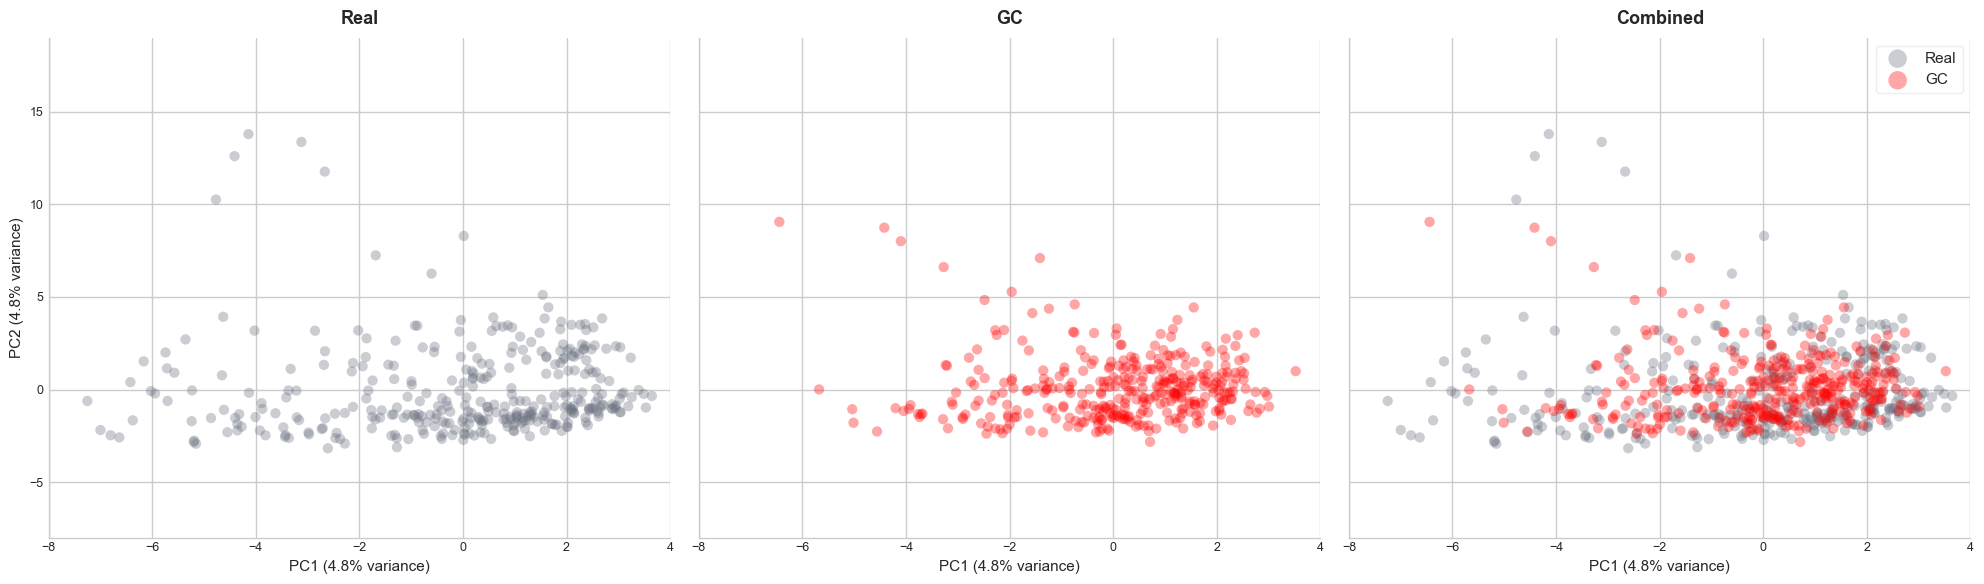

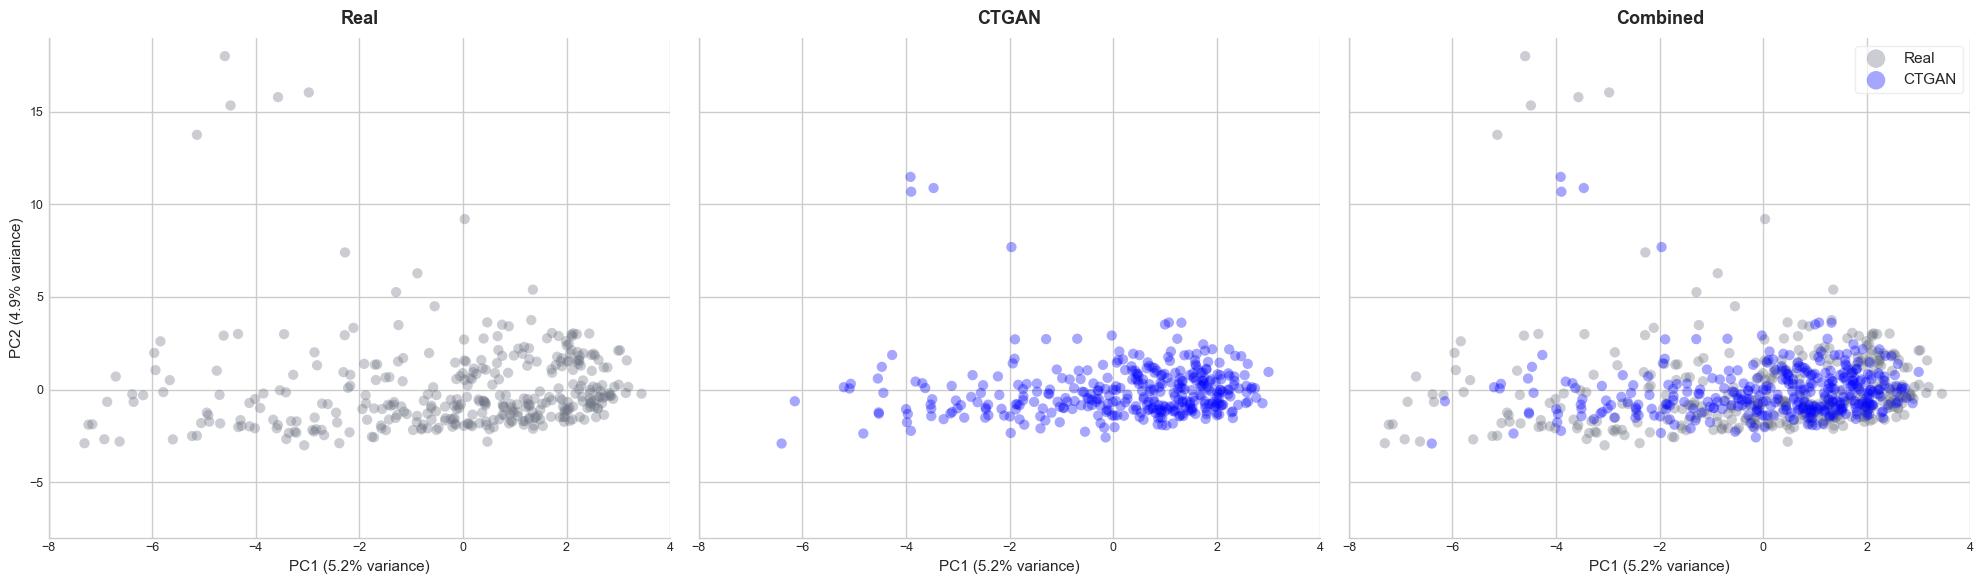

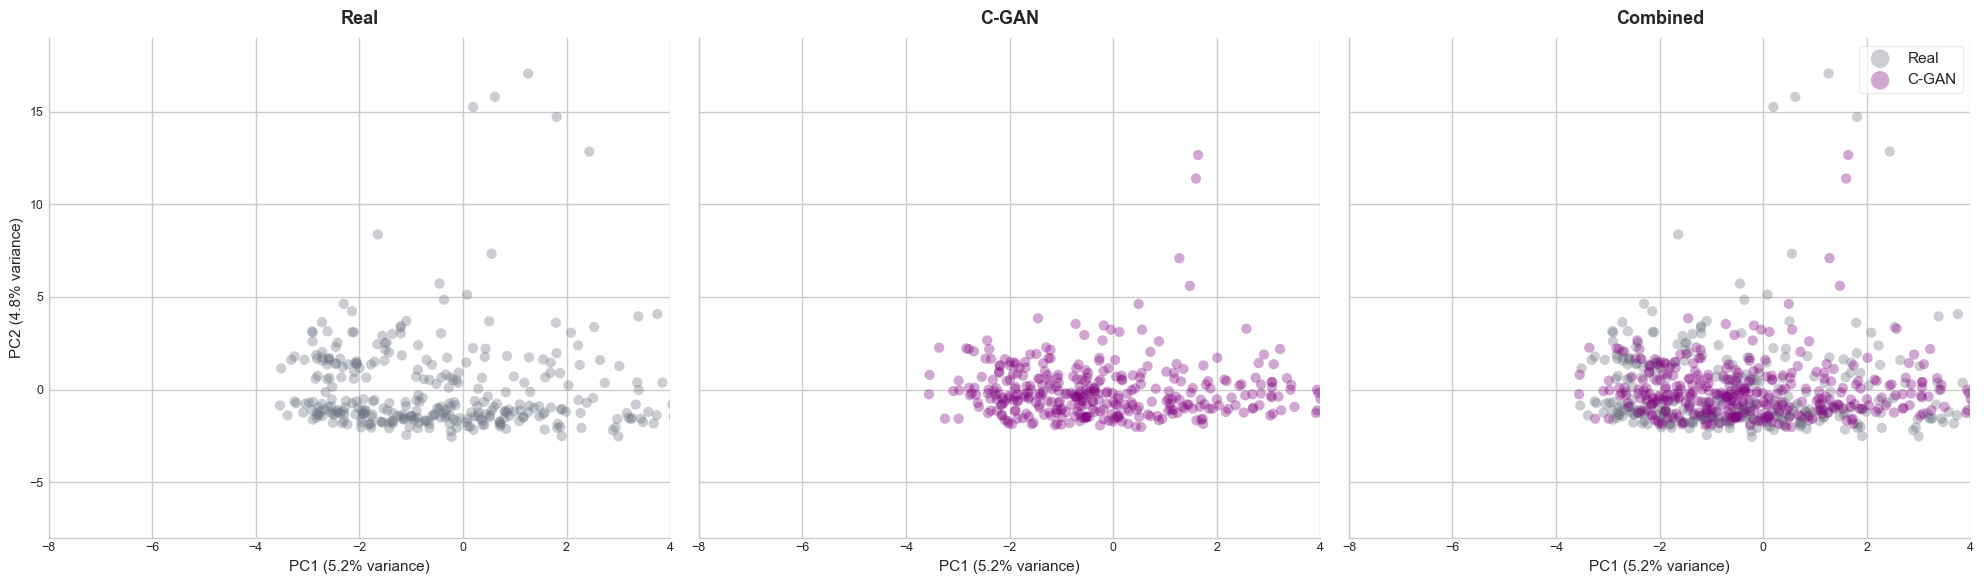

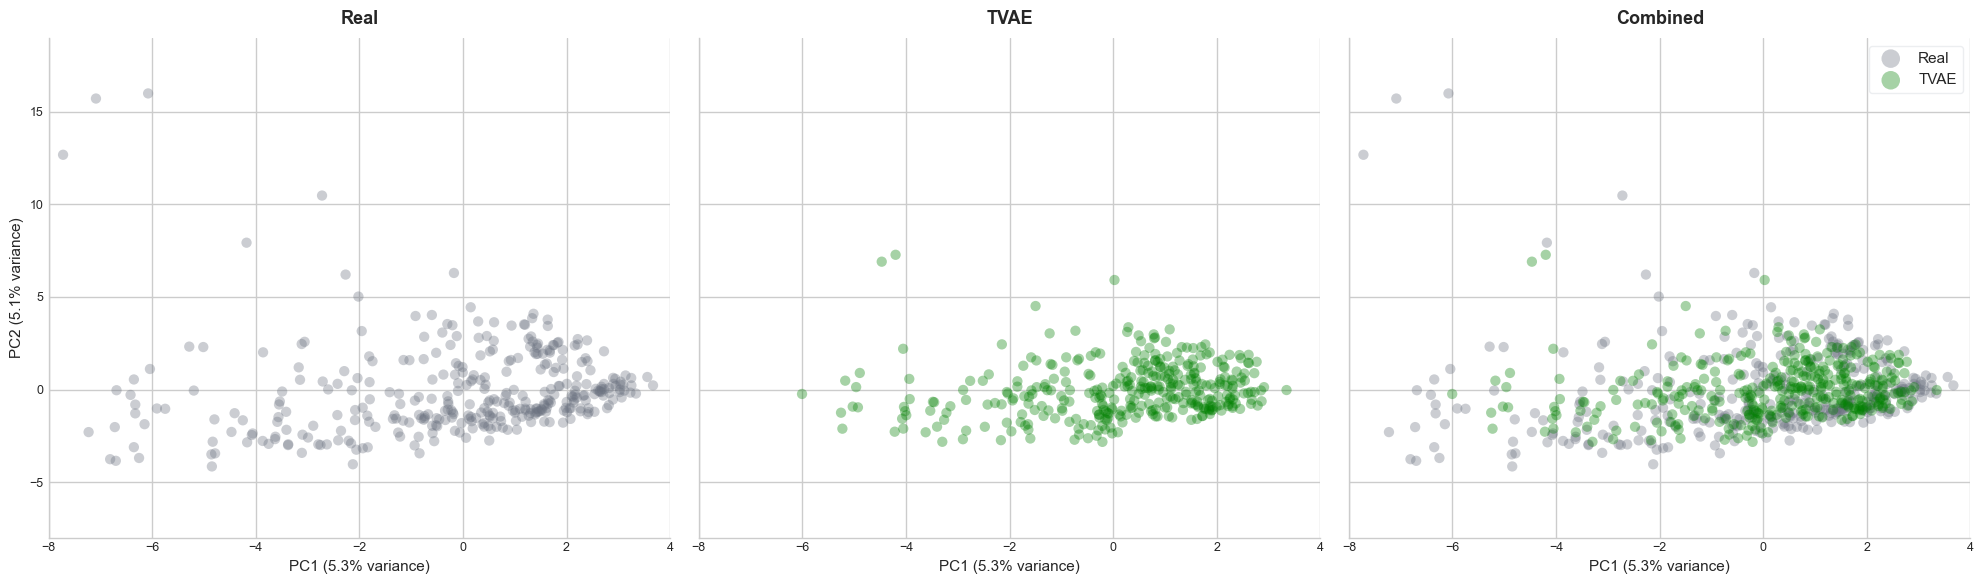

In [150]:
from Functions_graphs import plot_pca_overlap
for i in range(0, len(algoritmos)):
    plot_pca_overlap(df_real, dfs_synth[algoritmos[i]], algoritmos[i], colores)

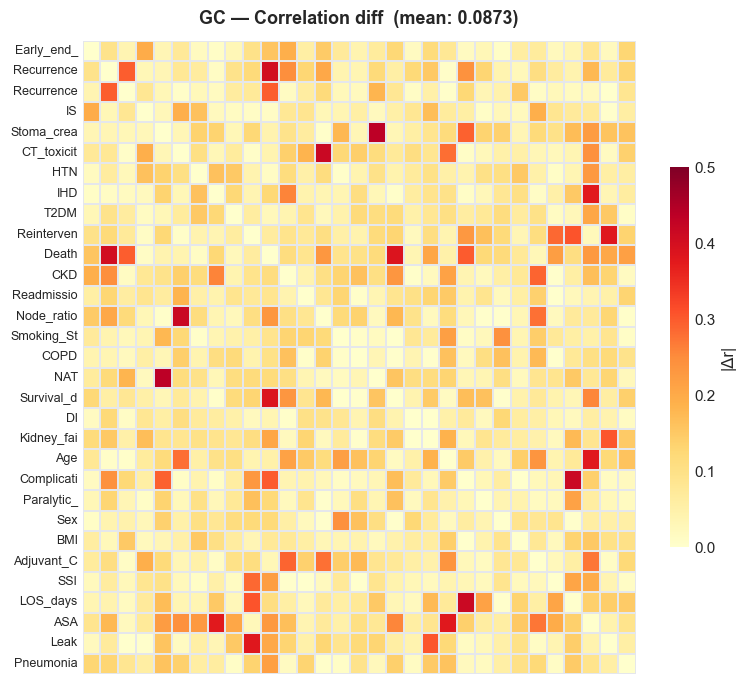

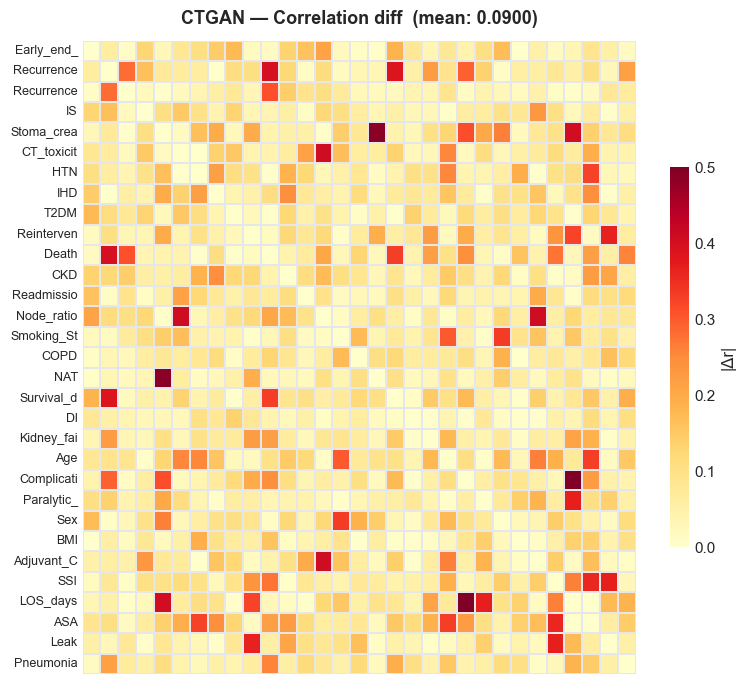

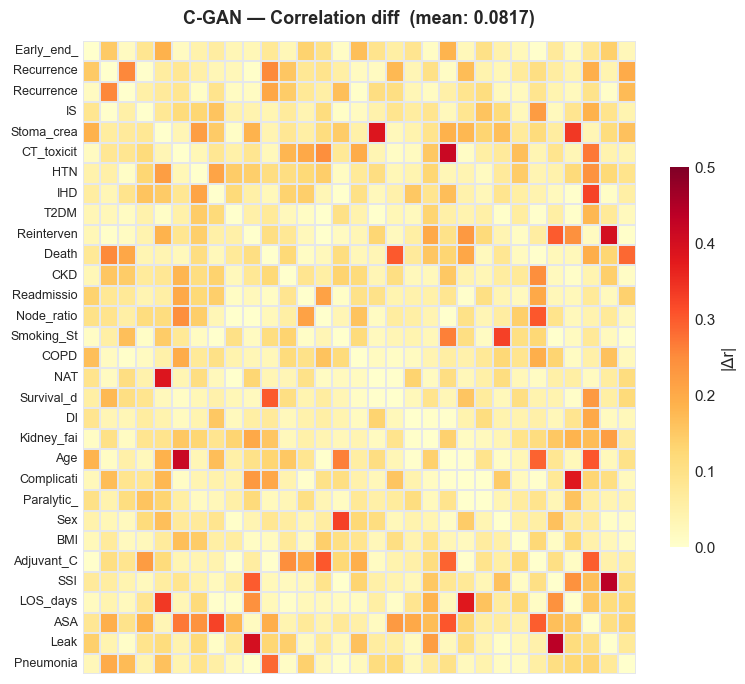

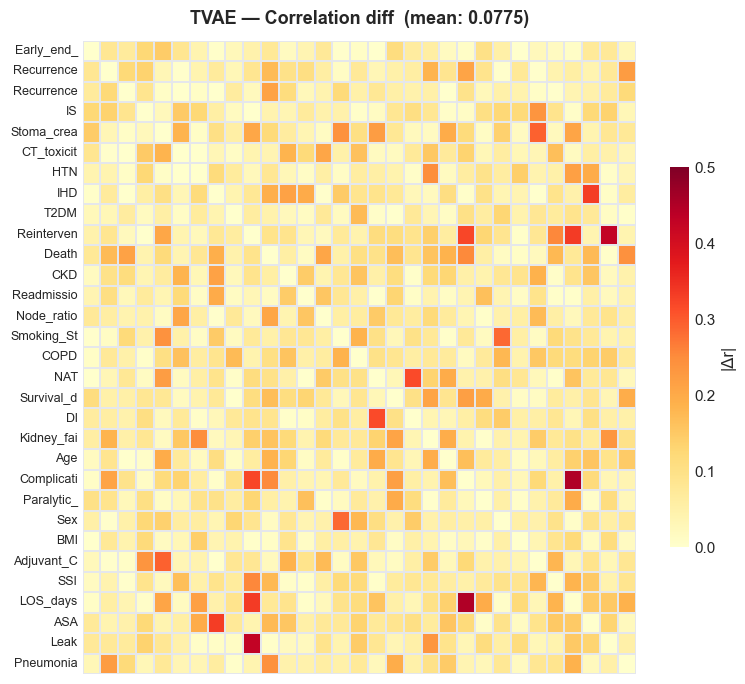

In [151]:
from Functions_graphs import corr_heatmap

for i in range(0, len(algoritmos)):
    corr_heatmap(df_real, dfs_synth[algoritmos[i]], algoritmos[i])

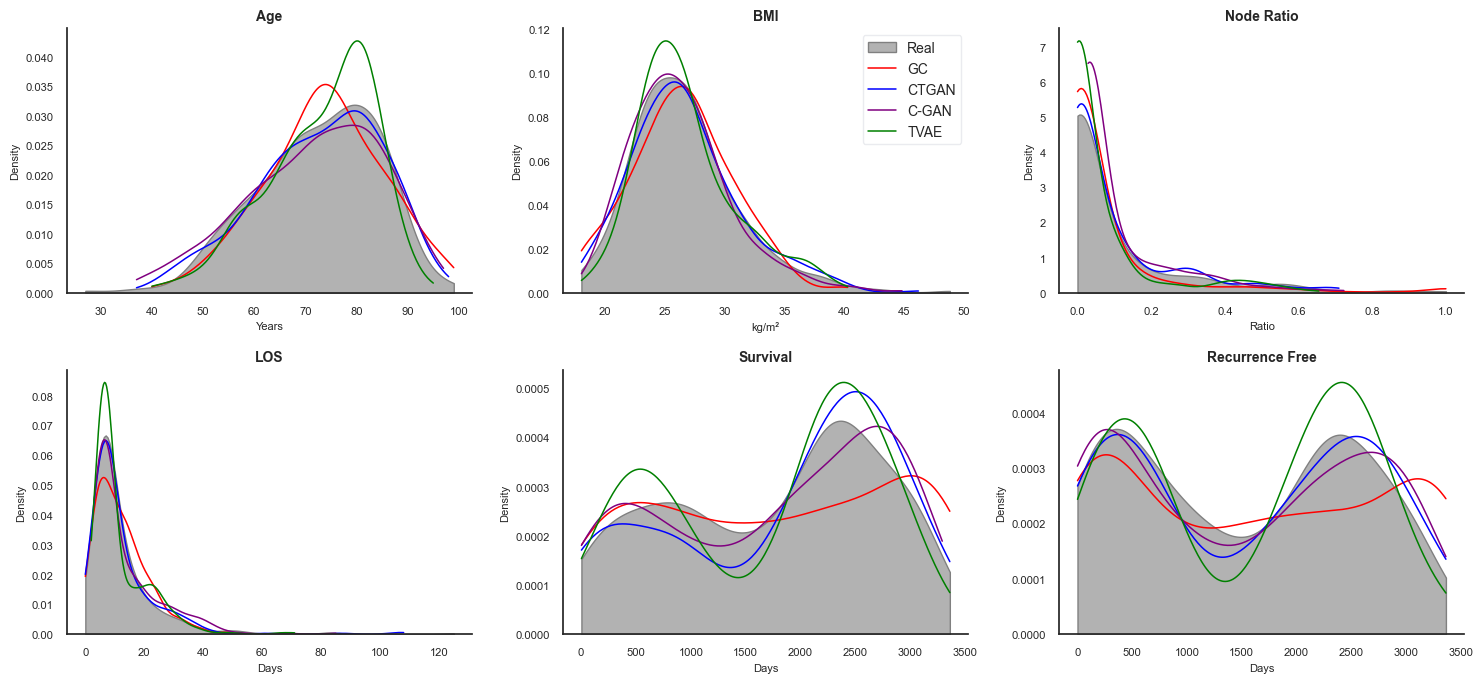

In [152]:
importlib.reload(Functions_graphs)
from Functions_graphs import plot_continuos_all

n_cols = 3
n_rows = math.ceil(len(columnas_continuas) / n_cols)

plot_continuos_all(df_real, dfs_synth, colores, n_cols, n_rows, columnas_continuas)


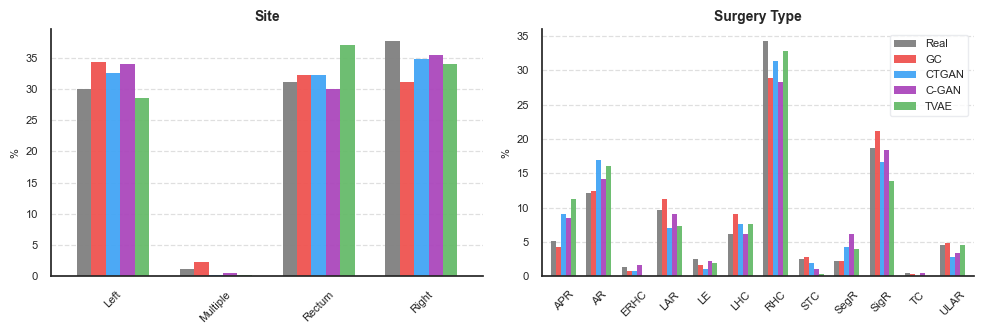

In [153]:
importlib.reload(Functions_graphs)
from Functions_graphs import plot_hist_all

cols_hist = [col for col in columnas_categoricas if len(df_real[col].value_counts())>=3]
cols_hist.remove('Patient_ID')
cols_selected = ["Site", "Surgery_type"]

colores_pastel = {
    "GC":    "#EF5350",   # rojo semi-pastel
    "CTGAN": "#42A5F5",   # azul semi-pastel
    "C-GAN": "#AB47BC",   # púrpura semi-pastel
    "TVAE":  "#66BB6A",   # verde semi-pastel
}
plot_hist_all(df_real, dfs_synth, colores_pastel, cols_selected, str('site_surgey'),2,1,45, str('right'), 8)

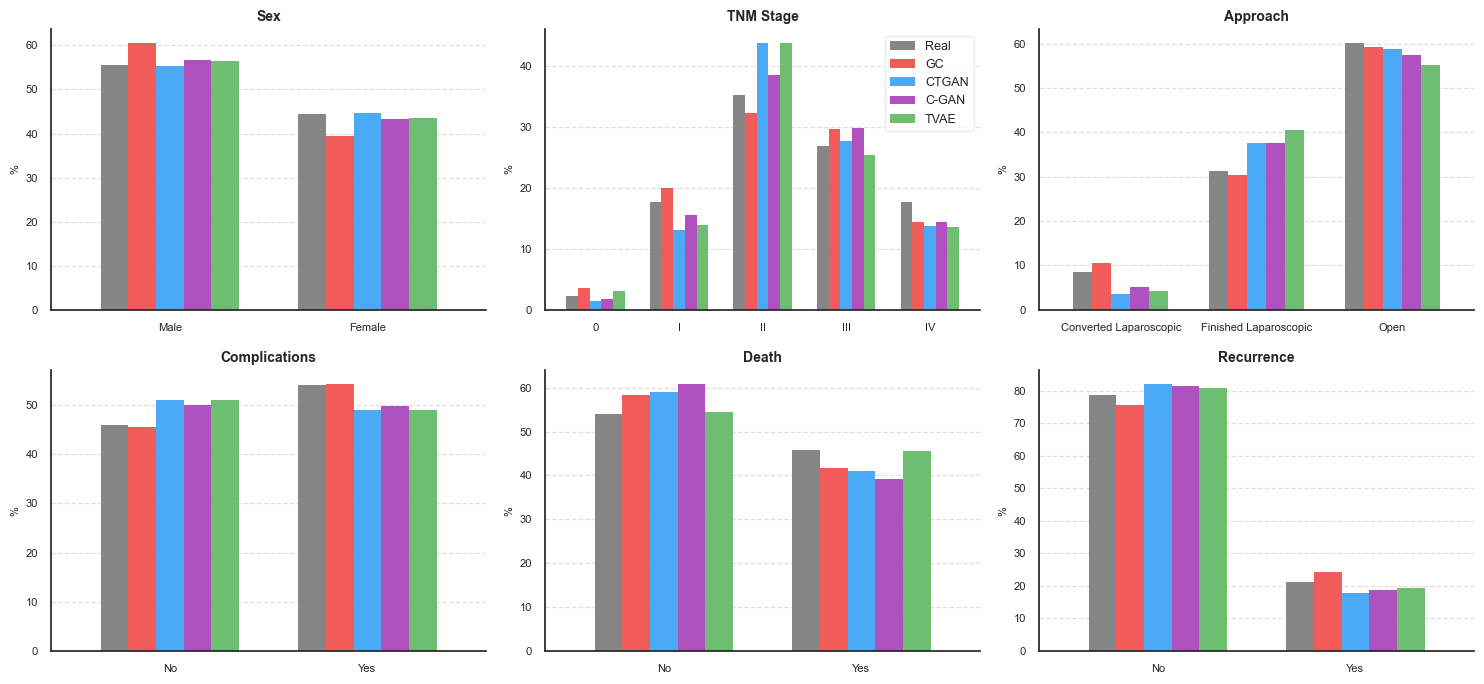

In [154]:
importlib.reload(Functions_graphs)
from Functions_graphs import plot_hist_all
paper_cols = ["Sex", "TNM_stage", "Approach", "Complications", "Death", "Recurrence"]
plot_hist_all(df_real, dfs_synth, colores_pastel, paper_cols, str('all_cat_bin'), 3, 1, 0, str('right'), 9)

In [155]:
importlib.reload(Functions_graphs)
from Functions_graphs import plot_bin_all
#plot_bin_all(df_real, dfs_synth, colores, columnas_categoricas, cols_hist)

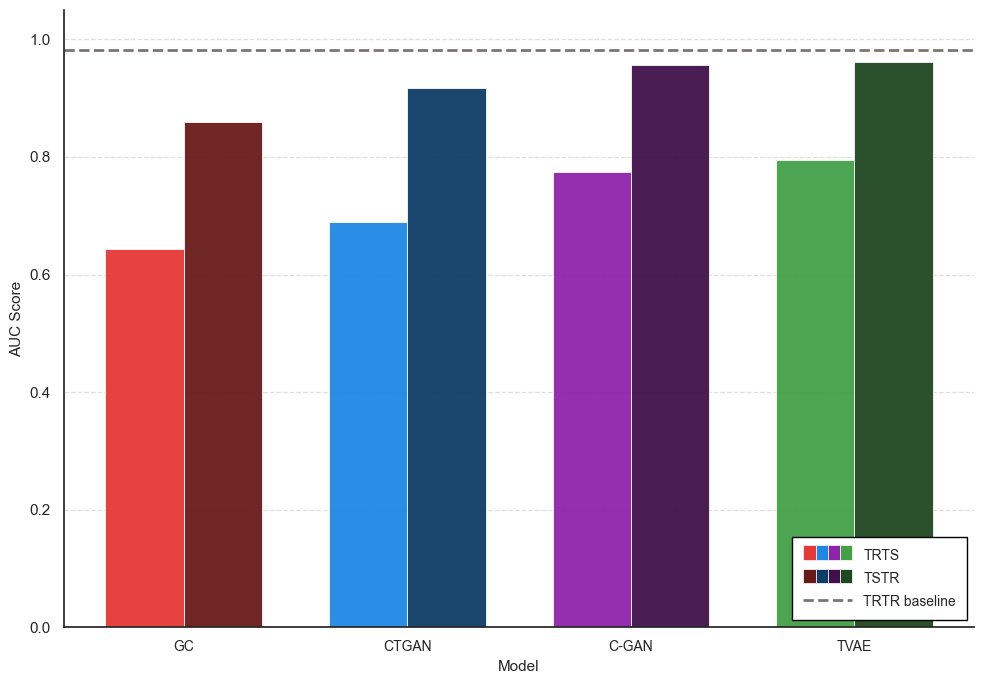

In [156]:
importlib.reload(Functions_graphs)
from Functions_graphs import *

results = []
for nombre, path in SYNTH_PATHS.items():
    df_synth = load_and_clean(path, ID_COL)
    r = compute_utility(df_train, df_test, df_synth, nombre, TARGET_COL)
    results.append(r)

df_results = pd.DataFrame(results)
df_results.to_excel("../plots/utility.xlsx", index=False, engine="openpyxl")

colores_utility = {
    "GC":    "#E53935",   # rojo
    "CTGAN": "#1E88E5",   # azul
    "C-GAN": "#8E24AA",   # púrpura
    "TVAE":  "#43A047",   # verde
}

plot_utility(results, colores_utility)

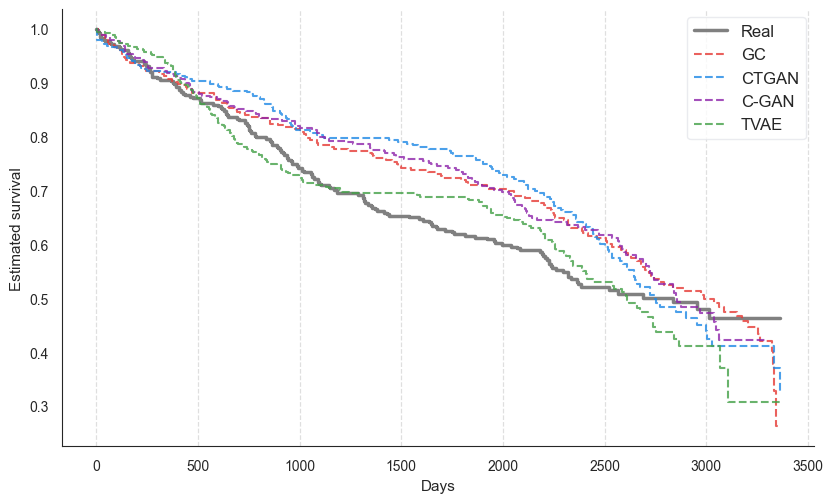

In [157]:
importlib.reload(Functions_graphs)
from Functions_graphs import km_analysis
km_analysis(df_real, dfs_synth, time_col, event_col, colores_utility)

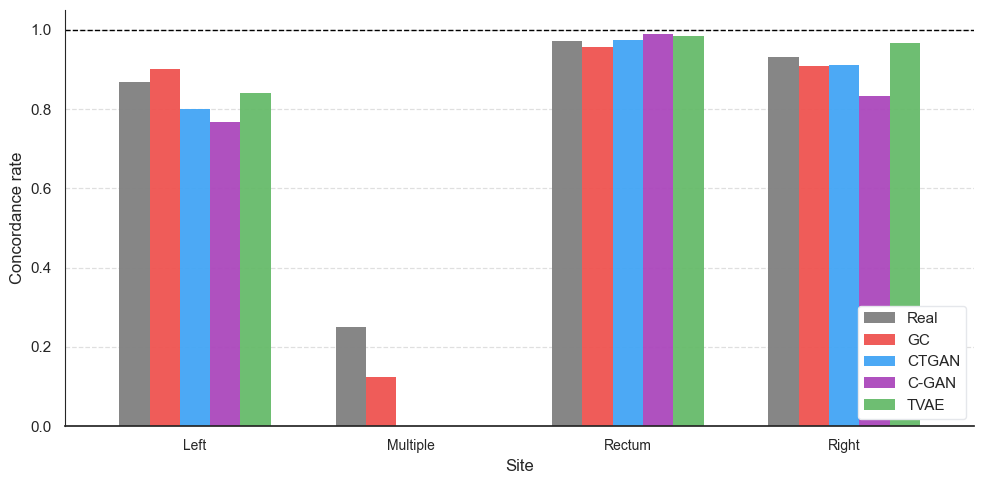

In [158]:
importlib.reload(Functions_graphs)
from Functions_graphs import plot_concordance_by_site
plot_concordance_by_site(df_real, dfs_synth, colores_pastel)